# Data Science Final Project
Navyata Neeraj
- Determining which households need social assistance

In [191]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Introduction

Today we will be focusing on the topic of social assistance - We create a classification model that determines which households need social assistance based on different criteria.

# Agenda

1. About Social Assistance 
2. Why is it important?
3. Problem Statement 
4. Data
5. Data Exploring & Cleaning
6. Understanding the Data (Visualisations)
7. The Classification Model
8. Optimizing the Model
9. Conclusion

# About Social Assistance

Social assistance is defined as a benefit in cash or in-kind, financed by the state (national or local) and usually provided on the basis of a means or income test (Ontario Government).

# Why is this important?

Many such government programmes do not adequately address inequality, assuming that economic growth alone is enough to close income gaps. A brief review of social assistance schemes done by the Applied Knowledge Services showcases:

- Public support systems and social assistance schemes have not expanded sufficiently to compensate for the decline of traditional systems
- There are new and increasing demands on families to provide support in the midst of regional and national trends such as greater mobility for employment, increased participation of women in the work force, and mounting inflation.
- Increased population and labour particiation rate has also overwhelmed the system in ensuring everyone in need receives this aid. 

# Problem Statement

This project aims to create a classification model - which will help determine which households require social assistance based on their income and living conditions. 

The aim is to help:
- The already overwhelmed system and ensure that more people can get their required aid
- Cities and municipalities in allocating budgets efficiently 
- Analyze the trends and patterns of the population who needs assistance 
- Plan for new programs 



# Data

Data source: Urban Mobility Survey, 2016, Brazil (Kaggle) 

The main objective of the Urban Mobility Survey was to investigate patterns and socioeconomic characteristics of the Federal District population. This information is the basis for understanting urban mobility within the studied area, by allowing the development of newer urban planning models.

The survey was conducted through interviews with all the residents of a set of randomly selected households, distributed among all Administrative Regions of the Federal District. The sample of households in the research was obtained from a stratified sampling strategy, according to spatial criteria and the average household income range of the microzones, to guarantee representativeness of the results.

A total of 19,252 complete and valid responses were obtained, with information on 61,358 residents. 



In [192]:
household_data = pd.read_csv('Household.csv', sep=';')
print(household_data)

       household_id  people_in_household  bathrooms  bedrooms  vehicles  \
0                 3                    2          2         2         1   
1                 4                    4          1         3         3   
2                 7                    3          2         3         1   
3                22                    3          4         4         2   
4                35                    3          2         3         1   
...             ...                  ...        ...       ...       ...   
19247        345420                    4          3         4         4   
19248        345421                    6          3         4         3   
19249        345422                    5          5         6         1   
19250        345423                    3          3         4         1   
19251        345424                    1          5         5         1   

       bicycles  motorcycles    dwelling_type  \
0             0            0  Brickwork house   
1

In [193]:
for col in household_data.columns:
    print(col)

household_id
people_in_household
bathrooms
bedrooms
vehicles
bicycles
motorcycles
dwelling_type
income
household_tenure
piped_water_supply
street_pavement
private_parking_space
year_of_newest_vehicle
domestic_worker
cable_tv
social_assistence
expf_household
macrozone
administrative_region


# Data Exploring & Cleaning

- Make sure no missing value
- No repeats
- Key columns are clean 


# 
Clarify which variables are key for our model. Some of them such as dwelling type, macrozone, expf_household, admin region, cable_tv, street_pavement is not the best judge of social assistance requirement in this dataset - so we will drop those. 

In [196]:
#drop the rest
household_data.drop(household_data.columns[[7,11,13,15,17,18,19]], axis = 1, inplace = True)

In [ ]:
#since income variable is a string - we need to change it to values so that it can be used for further analysis. 


In [197]:
#To check whether it needs changing off values - we use this code

household_data['income'].unique()

array(['More than R$ 4,400 and less than R$ 8,800',
       'More than R$ 1,760 and less than R$ 2,640',
       'More than R$ 2,640 and less than R$ 4,400',
       'More than R$ 8,800 and less than R$ 13,200',
       'More than R$ 440 and less than R$ 880',
       'More than R$ 880 and less than R$ 1,760',
       'More than R$ 13,200 and less than R$ 17,600', nan,
       'Has no income', 'More than R$ 22,000 and less than R$ 26,400',
       'R$ 440 or less', 'More than R$ 17,600 and less than R$ 22,000',
       'More than R$ 26,400'], dtype=object)

In [198]:
#Thus, we take the midpoint of the various income ranges and replace the data with the midpoint value

household_data['income'] = household_data['income'].replace('More than R$ 1,760 and less than R$ 2,640', 2200)
household_data['income'] = household_data['income'].replace('More than R$ 4,400 and less than R$ 8,800', 6600)
household_data['income'] = household_data['income'].replace('More than R$ 2,640 and less than R$ 4,400', 3520)
household_data['income'] = household_data['income'].replace('More than R$ 8,800 and less than R$ 13,200', 11000)
household_data['income'] = household_data['income'].replace('More than R$ 440 and less than R$ 880', 660)
household_data['income'] = household_data['income'].replace('More than R$ 880 and less than R$ 1,760', 1320)
household_data['income'] = household_data['income'].replace('More than R$ 13,200 and less than R$ 17,600', 15400)
household_data['income'] = household_data['income'].replace('More than R$ 22,000 and less than R$ 26,400', 24200 )
household_data['income'] = household_data['income'].replace('R$ 440 or less', 220)
household_data['income'] = household_data['income'].replace('More than R$ 17,600 and less than R$ 22,000', 19800)
household_data['income'] = household_data['income'].replace('More than R$ 26,400', 26400)
household_data['income'] = household_data['income'].replace('Has no income', 0)
household_data['income'] = household_data['income'].replace(np.nan, 0)

In [199]:
#same as above for household_tenure

household_data['household_tenure'] = household_data['household_tenure'].replace('Owned', 1)
household_data['household_tenure'] = household_data['household_tenure'].replace('Rented', 0)
household_data['household_tenure'] = household_data['household_tenure'].replace('Living as a guest', 0)
household_data['household_tenure'] = household_data['household_tenure'].replace('Other type', 0)
household_data['household_tenure'] = household_data['household_tenure'].replace('In process of owning', 1)
household_data['household_tenure'] = household_data['household_tenure'].replace('In concession', 0)
household_data['household_tenure'] = household_data['household_tenure'].replace('Subsidized by work company', 0)
household_data['household_tenure'] = household_data['household_tenure'].replace(np.nan, 0)

In [200]:
#same as above for social assistence
household_data['social_assistence'] = household_data['social_assistence'].replace('Yes', 1)
household_data['social_assistence'] = household_data['social_assistence'].replace('No', 0)
household_data['social_assistence'] = household_data['social_assistence'].replace(np.nan, 0)

In [201]:
#same as above for piped water supply
household_data['piped_water_supply'] = household_data['piped_water_supply'].replace('Yes, available at least in one room', 1)
household_data['piped_water_supply'] = household_data['piped_water_supply'].replace('No', 0)
household_data['piped_water_supply'] = household_data['piped_water_supply'].replace('Yes, but only connected to a tap outside of the house (in the property)', 0.5)


In [202]:
#same as above for private_parking_space
household_data['private_parking_space'] = household_data['private_parking_space'].replace('Available', 1)
household_data['private_parking_space'] = household_data['private_parking_space'].replace('Not available', 0)
household_data['private_parking_space'] = household_data['private_parking_space'].replace(np.nan, 0)


In [203]:
#same as above for domestic_worker
household_data['domestic_worker'] = household_data['domestic_worker'].replace('No domestic workers', 0)
household_data['domestic_worker'] = household_data['domestic_worker'].replace('Yes, occasional', 1)
household_data['domestic_worker'] = household_data['domestic_worker'].replace('Yes, regular', 1)
household_data['domestic_worker'] = household_data['domestic_worker'].replace('Yes, living-in', 1)
household_data['domestic_worker'] = household_data['domestic_worker'].replace(np.nan, 0)



In [204]:
household_data.isnull().sum()

household_id             0
people_in_household      0
bathrooms                0
bedrooms                 0
vehicles                 0
bicycles                 0
motorcycles              0
income                   0
household_tenure         0
piped_water_supply       0
private_parking_space    0
domestic_worker          0
social_assistence        0
dtype: int64

# Understanding the Data
- Variables 
- decribe/ mean median 


In [205]:
household_data.describe(include='all')


,household_id,people_in_household,bathrooms,bedrooms,vehicles,bicycles,motorcycles,income,household_tenure,piped_water_supply,private_parking_space,domestic_worker,social_assistence
count,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000,19252.000000
mean,132270.295761,3.187097,1.938188,2.632298,1.006389,0.637752,0.092302,4215.904841,0.675878,0.975743,0.810565,0.199044,0.070382
std,113153.061358,1.465941,2.612911,2.598174,0.947158,0.969154,0.355064,5446.493172,0.468058,0.117696,0.391864,0.399292,0.255797
min,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,22326.500000,2.000000,1.000000,2.000000,0.000000,0.000000,0.000000,660.000000,0.000000,1.000000,1.000000,0.000000,0.000000
50%,109376.500000,3.000000,2.000000,3.000000,1.000000,0.000000,0.000000,2200.000000,1.000000,1.000000,1.000000,0.000000,0.000000
75%,229269.250000,4.000000,2.000000,3.000000,1.000000,1.000000,0.000000,6600.000000,1.000000,1.000000,1.000000,0.000000,0.000000
max,345424.000000,13.000000,303.000000,311.000000,10.000000,11.000000,20.000000,26400.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# Visualizing the data
- Consolidate the understanding of data with mini conclusions for each visaluations 
- Histograms
- Line Plots
- Seaborn Charts
- Heat maping 
- Distribution pie charts

In [206]:
import seaborn as sns

sns.set_style('whitegrid')



# 
Firstly, we will create a heatmap to see if any variables are heavily correlated and need to be dropped

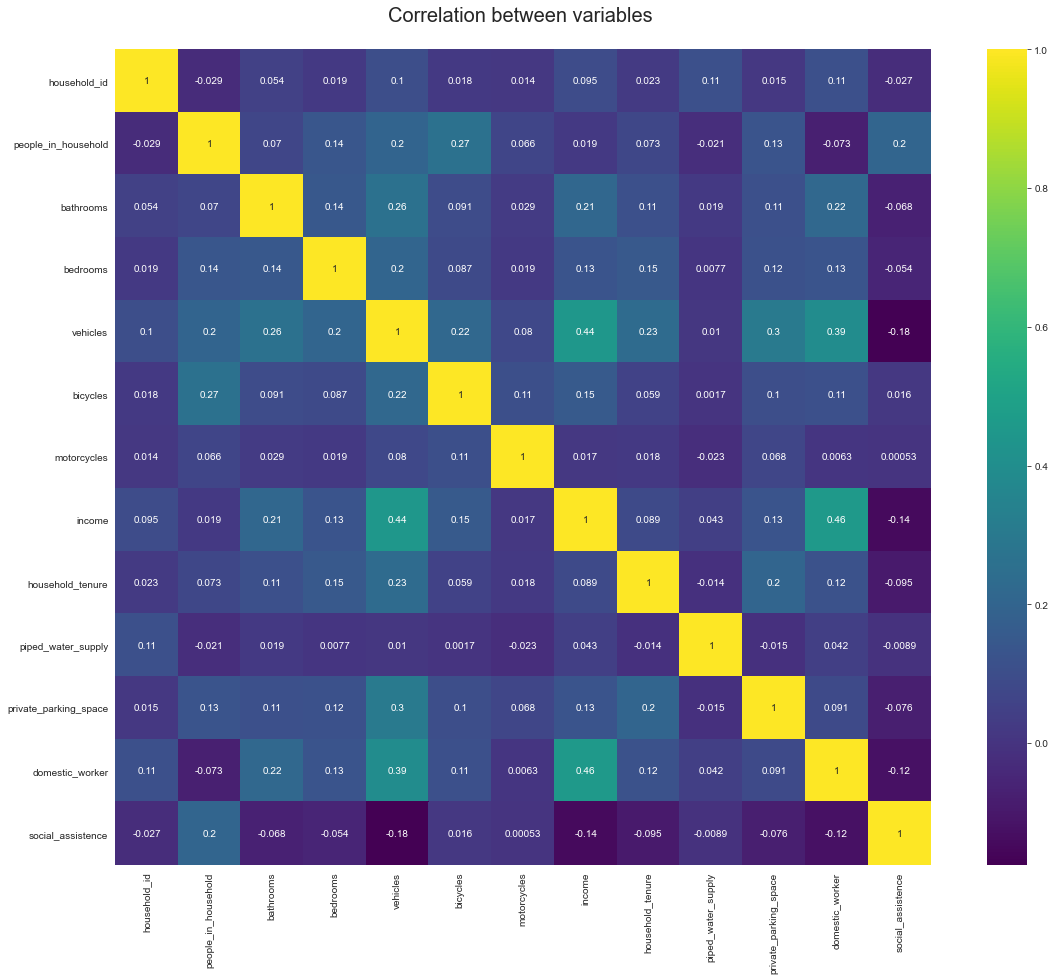

In [207]:
corr = household_data.corr(method='pearson')
f, ax = plt.subplots(figsize=(20, 15))

# Draw the heatmap using seaborn
sns.heatmap(corr, vmax=1., square=True, annot= True,cmap= "viridis")
plt.title("Correlation between variables \n", fontsize=20)
plt.show()

If you look at the map, you can see a scale wherein if its in a yellow shade, its heavily correlated. However, here most are in the blue zone which means the variables are independent. 

Now, we can look at a histogram of the income - showing the income split. As you can see, most participants were in the lower than average income range. 

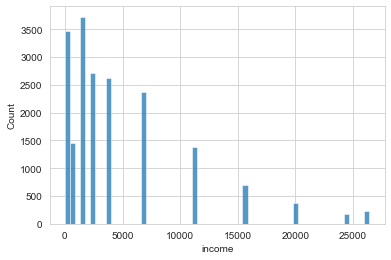

In [209]:
sns.histplot(household_data['income'])
plt.show()

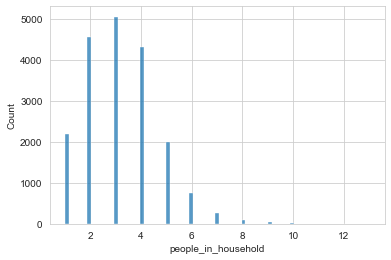

In [271]:
sns.histplot(household_data['people_in_household'])
plt.show()

Next, to further understand the data, we can also make a scatter plot - in this case of the number of vehicles owned by each household. 

In [212]:
household_data['total_vehicles'] = household_data['vehicles'] + household_data['motorcycles']
print(household_data['total_vehicles'])

0        1
1        3
2        1
3        2
4        1
        ..
19247    4
19248    3
19249    1
19250    1
19251    1
Name: total_vehicles, Length: 19252, dtype: int64


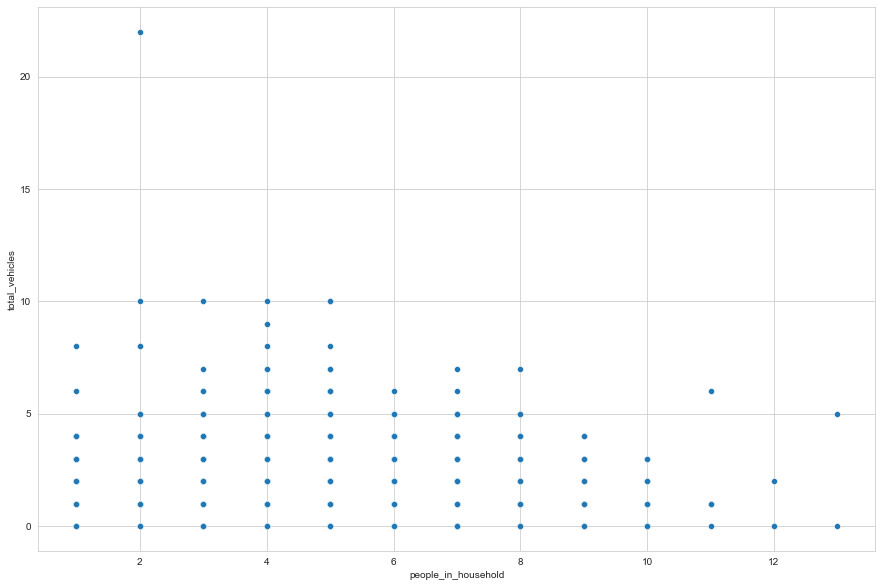

In [213]:
plt.figure(figsize = (15,10))
sns.scatterplot(data=household_data, x='people_in_household', y='total_vehicles')  
plt.show()
# lowering alpha makes points slightly more transparent

The total number of vehicles vs. people in household. 

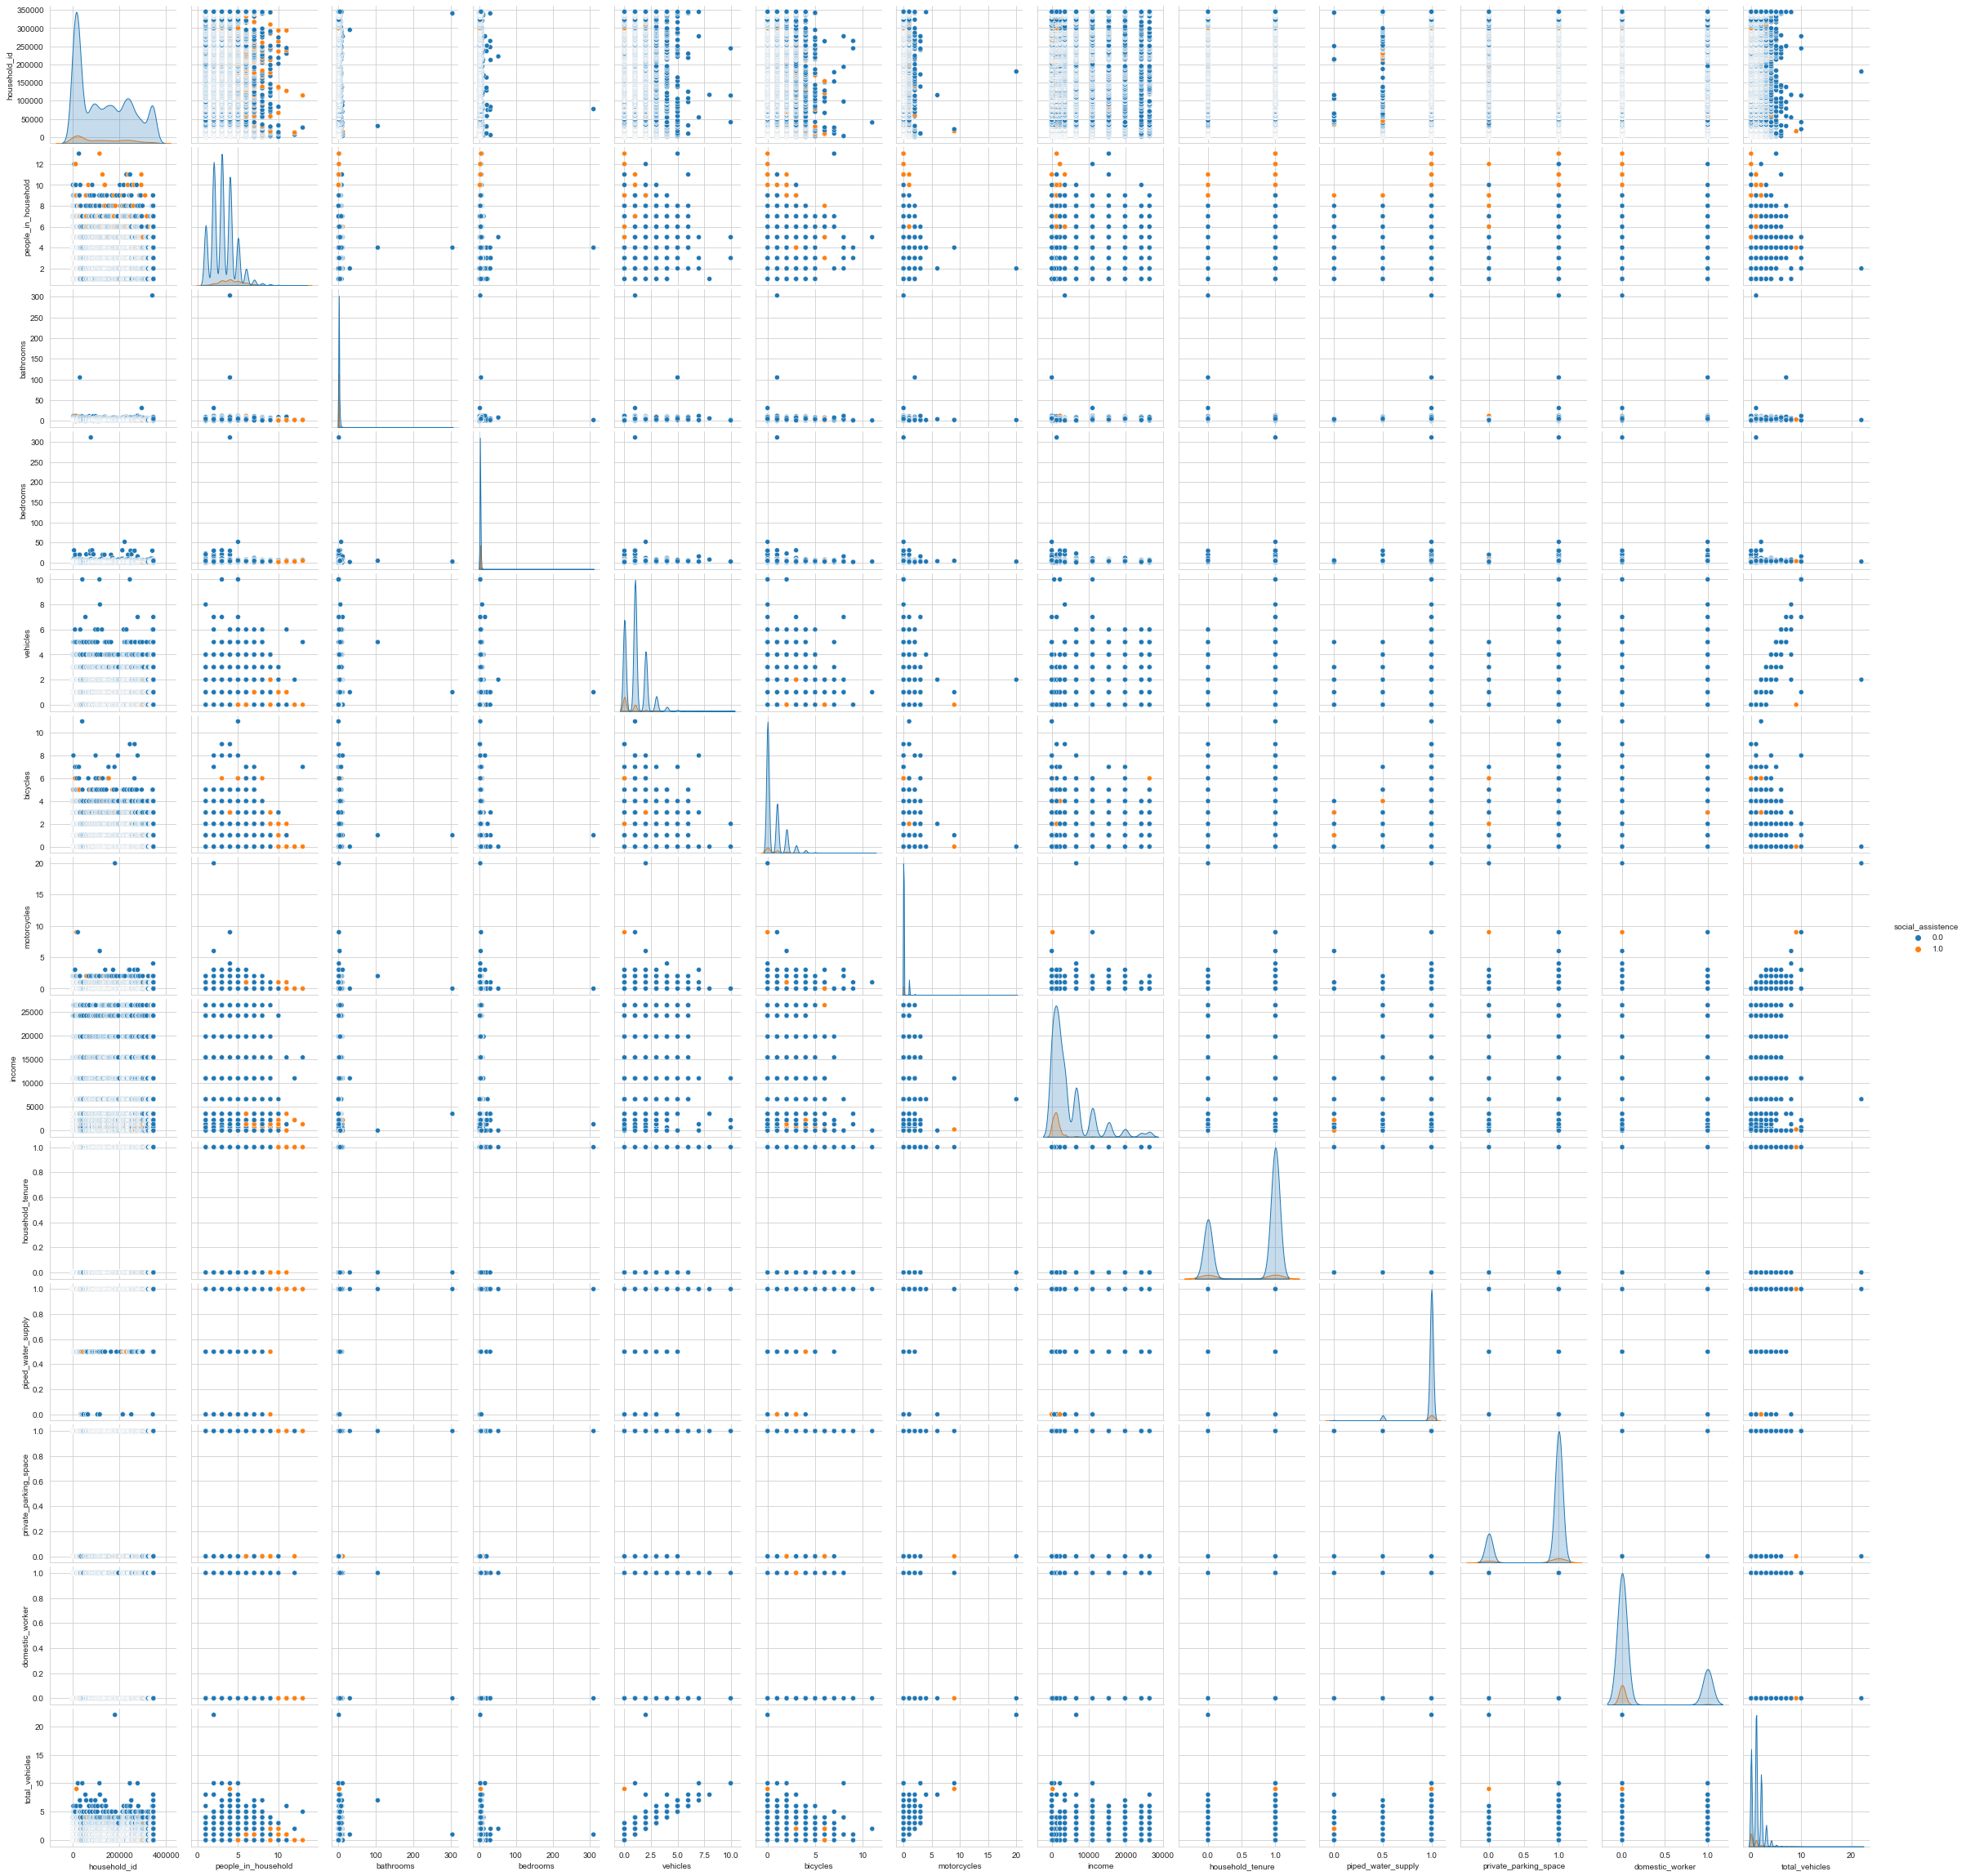

In [277]:
sns.pairplot(household_data, hue="social_assistence")

# Training and Testing

Before building the model - we use a train and test dataset, my split was 70-30 

In [238]:
from sklearn import model_selection, metrics

In [243]:
# Split our data into x and y, dropping the social assistance variable in the x since that is to be predicted by y - making y only social assistance
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(household_data.drop('social_assistence',1), household_data['social_assistence'], test_size=0.30, random_state=5)

In [244]:
x_train #ensuring it randomized, notice the different household_id

,household_id,people_in_household,bathrooms,bedrooms,vehicles,bicycles,motorcycles,income,household_tenure,piped_water_supply,private_parking_space,domestic_worker,total_vehicles
7091,41596,3,3,3,2,0,0,15400.0,1.0,1.0,1.0,0.0,2
11534,158010,3,2,4,1,0,0,1320.0,1.0,1.0,1.0,0.0,1
6774,29790,2,2,2,0,0,0,2200.0,1.0,1.0,0.0,0.0,0
15778,250847,2,1,1,0,0,0,2200.0,0.0,1.0,0.0,0.0,0
7037,39998,4,4,4,1,0,0,0.0,1.0,1.0,1.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1032,4251,2,2,3,1,1,0,3520.0,1.0,1.0,1.0,0.0,1
5520,25675,1,1,2,1,1,0,6600.0,1.0,1.0,1.0,0.0,1
3046,12244,2,2,3,0,2,0,3520.0,1.0,1.0,1.0,0.0,0
18638,342618,3,1,1,0,0,0,3520.0,1.0,1.0,1.0,0.0,0


In [245]:
x_test

,household_id,people_in_household,bathrooms,bedrooms,vehicles,bicycles,motorcycles,income,household_tenure,piped_water_supply,private_parking_space,domestic_worker,total_vehicles
7396,57746,2,1,2,0,0,0,2200.0,1.0,1.0,1.0,0.0,0
18176,340460,2,3,3,1,0,0,15400.0,1.0,1.0,0.0,1.0,1
14581,230320,3,2,3,3,0,0,0.0,1.0,1.0,1.0,0.0,3
212,1207,4,1,2,1,1,0,3520.0,1.0,1.0,1.0,0.0,1
18767,343337,5,1,2,1,2,0,0.0,1.0,1.0,1.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
13436,212907,3,1,2,0,0,0,1320.0,1.0,1.0,0.0,0.0,0
13264,207618,3,1,3,2,0,0,3520.0,1.0,1.0,1.0,0.0,2
2119,8714,3,2,3,2,3,0,3520.0,1.0,1.0,1.0,1.0,2
18981,344342,4,3,4,2,2,0,19800.0,1.0,1.0,1.0,1.0,2


In [246]:
y_train

7091     0.0
11534    0.0
6774     0.0
15778    0.0
7037     0.0
        ... 
1032     0.0
5520     0.0
3046     0.0
18638    0.0
2915     0.0
Name: social_assistence, Length: 13476, dtype: float64

In [247]:
y_test

7396     0.0
18176    0.0
14581    0.0
212      0.0
18767    1.0
        ... 
13436    0.0
13264    0.0
2119     0.0
18981    0.0
10656    1.0
Name: social_assistence, Length: 5776, dtype: float64

In [248]:
#from sklearn.tree import DecisionTreeClassifier
#from sklearn.tree import export_graphviz
#from subprocess import call
#from IPython.display import SVG
#from graphviz import Source




In [249]:
from sklearn import tree

#initialising the decision tree with a max_depth of 2 and training the model on the training data.

soc_assist = tree.DecisionTreeClassifier(max_depth=2)
soc_assist.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=2)

In [250]:
from sklearn import metrics

# We use the model to predict the test_encoded data
test_data = soc_assist.predict(x_test)

print(metrics.accuracy_score(y_test, test_data))

0.9265927977839336


So 0.926 is the R squared value of the model. This means that on average, 92% of the variation in the output variable is explained by the input variables

# Optimizing the model

Now we can test with various depths and see which model parameters are the best 


In [251]:
# A decision tree with max_depth = 2
soc_assist2 = tree.DecisionTreeClassifier(max_depth=2)
soc_assist2.fit(x_train, y_train)

# Print train and test accuracy scores
print(soc_assist2.score(x_train, y_train))
print(soc_assist2.score(x_test, y_test))

0.9309142178688038
0.9265927977839336


In [252]:
# A decision tree with max_depth = 6
soc_assist3 = tree.DecisionTreeClassifier(max_depth=6)
soc_assist3.fit(x_train, y_train)

# Print train and test accuracy scores
print(soc_assist3.score(x_train, y_train))
print(soc_assist3.score(x_test, y_test))

0.9362570495696052
0.9264196675900277


In [253]:
# A decision tree with max_depth = 12
soc_assist4 = tree.DecisionTreeClassifier(max_depth=12)
soc_assist4.fit(x_train, y_train)

# Print train and test accuracy scores
print(soc_assist4.score(x_train, y_train))
print(soc_assist4.score(x_test, y_test))

0.9663846838824577
0.9089335180055401


After doing a couple of them manually, we can actually loop through a range:

In [254]:
depth_values = range(1, 15)

# Create placeholder lists to append our scores to
train_scores = []
test_scores = []


# Loop through each depth value
for d in depth_values:

    # Create and fit a decision tree with that depth
    dt = tree.DecisionTreeClassifier(max_depth=d)
    dt.fit(x_train, y_train)

    # Calculate train and test accuracies
    train_acc = dt.score(x_train, y_train)
    test_acc = dt.score(x_test, y_test)

    # Append them to our lists
    train_scores.append(train_acc)
    test_scores.append(test_acc)

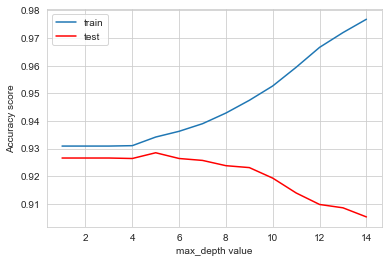

In [255]:
plt.figure()
plt.plot(depth_values, train_scores, label='train')
plt.plot(depth_values, test_scores, label='test', c='r')
plt.xlabel('max_depth value')
plt.ylabel('Accuracy score')
plt.legend()
plt.show()

This graph shows the R squared value for the training and testing data for various depths. Notice how at about max depth 6 the data diverges - this shows that the model is starting to overfit. Hence, in my opinion, the ideal parameters is at max depth = 5 - as thats the highest R squared value without over fitting. 

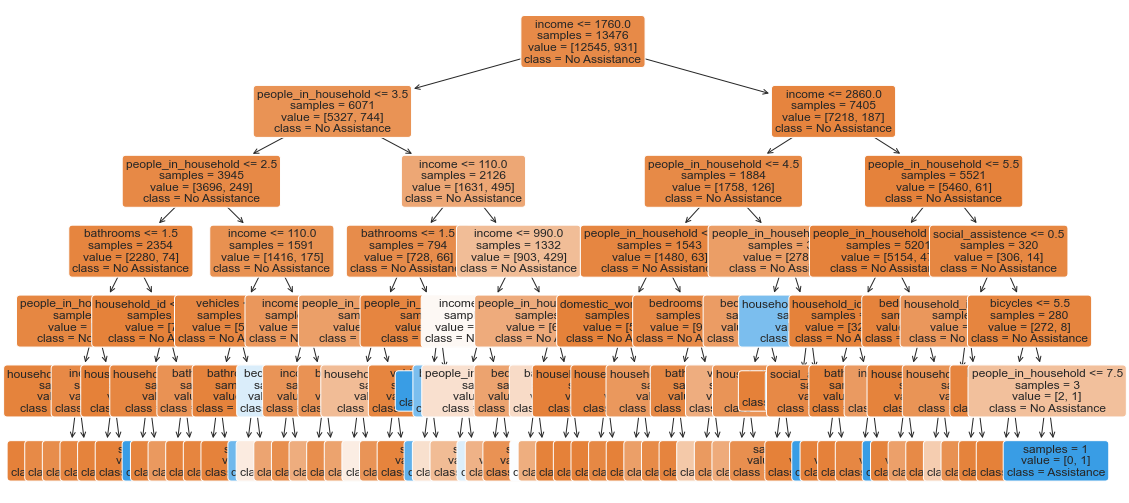

In [283]:
from sklearn.tree import plot_tree

# size for our tree figure
fig, ax = plt.subplots(figsize=(18, 9))

# Use sklearn's plot_tree() function
plot_tree(soc_assist3,
          feature_names = household_data.columns,
          class_names = ['No Assistance', 'Assistance'],
          rounded=True,
          impurity=False,
          filled=True,
          ax=ax,
          fontsize=12);

# Conclusion

To conclude, this model can assess the households that need social assistance. This is based on the training and testing of the model, and since we saw the model had an R squared value of approx 93, this means that on average, 92% of the variation in the output variable is explained by the input variables - thus giving a high accuracy score. 

However, its important to acknowledge that this model does not have all the parameters that would be used to fully asses whether a household requires social assistance - if done again, I would include variables such as education, loans, age, years in workforce and so on. 

Thank you. 